# Random Forest

This notebook trains a Random Forest model to predict the death risk of leukemia patients from clinical and molecular data.


The objective is therefore twofold:
1. Evaluate the ability of Random Forest to classify patients according to their risk.
2. Analyze the quality of its probabilities before any calibration.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.eval_utils import full_evaluation
from src.modeltrainer import ModelML, find_existing_model

## Load the processed data

The pairs built in `00_data_processing.ipynb` and imputed by `01_impute_missing_values.sh` are loaded from `data/processed_data_imputed.xlsx` (train / calibration / test sheets).

In [2]:
# =============================================================================
# CELL 1: LOAD DATA
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Load the three splits
print("Loading data...")

train_data = pd.read_excel(DATA_PATH, sheet_name='train')
cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Split features / target
X_train = train_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_train = train_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print("Data loaded:")
print(f"   - Train: {X_train.shape[0]} lignes, {X_train.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes")
print(f"   - Target distribution (train): {y_train.value_counts().to_dict()}")

Loading data...
Data loaded:
   - Train: 445575 lignes, 81 features
   - Test: 56938 lignes
   - Target distribution (train): {0: 249063, 1: 196512}


We check if the trained model doesn't already exist, if it does we load it otherwise we train it.


In [3]:
# =============================================================================
# CELL 2: LOAD OR TRAIN THE RANDOM FOREST MODEL
# =============================================================================


# Configuration
MODEL_DIR = 'models'
MODEL_TYPE = 'RandomForest'  # 'LogisticRegression', 'RandomForest', 'XGBoost'



# Initialise the trainer
trainer = ModelML(
    x_train=X_train,
    x_test=X_test,
    y_train=y_train,
    y_test=y_test
)

# Reuse a saved model if one exists, otherwise tune and train
existing_model = find_existing_model(MODEL_DIR, MODEL_TYPE)

if existing_model:
    print(f"Found saved model: {existing_model}")
    trainer.load_model(existing_model)
else:
    print(f"No saved {MODEL_TYPE} model found. Training...")
    
    trainer.tune_random_forest(
        param_grid={
            'n_estimators': [50, 100, 200],
            'max_depth': [3, 5, 10, None],
            'min_samples_leaf': [1, 2],
            'max_features': ['sqrt']
        },
        method='random',
        n_iter=20,
        cv=5,
        scoring='roc_auc'
    )
    
    trainer.save_model()
    print("Model trained and saved")

print(f"\nActive model: {trainer.model_name}")
print(f"   Parameters: {trainer.best_params}")

No saved RandomForest model found. Training...

Hyperparameter search (RANDOM)
   Model: random_forest_tuned
   Scoring: roc_auc
   CV folds: 5
   Parameters searched: ['n_estimators', 'max_depth', 'min_samples_leaf', 'max_features']
Fitting 5 folds for each of 20 candidates, totalling 100 fits


/mnt/12f6cfec-e85b-498f-b7be-df4d2207236a/home-mouad/venvs/masef/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(



Best parameters found:
   - n_estimators: 200
   - min_samples_leaf: 1
   - max_features: sqrt
   - max_depth: None
   - Best CV Score (roc_auc): 0.9798

Results:
   - Train Accuracy: 1.0000
   - Test Accuracy:  0.7026
Model saved: models/random_forest_tuned.pkl
Parameters saved: models/random_forest_tuned_params.json
Model trained and saved

Active model: random_forest_tuned
   Parameters: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}



TEST SET EVALUATION

FULL EVALUATION: random_forest_tuned_test
EVALUATION METRICS

Classification metrics:
----------------------------------------
   Accuracy                 : 0.7026
   Balanced_Accuracy        : 0.6970
   Precision                : 0.6848
   Recall_Sensitivity       : 0.6371
   Specificity              : 0.7569
   F1_Score                 : 0.6601
   Matthews_Corr_Coef       : 0.3972
   Cohen_Kappa              : 0.3964

Probabilistic metrics:
----------------------------------------
   ROC_AUC                  : 0.7696
   PR_AUC                   : 0.7246
   Brier_Score              : 0.1948
   Log_Loss                 : 0.5726

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Class 0       0.72      0.76      0.74     31128
     Class 1       0.68      0.64      0.66     25810

    accuracy                           0.70     56938
   macro avg       0.70      0.70      0.70     56938
weighted avg       0.70      0.70      0.70    

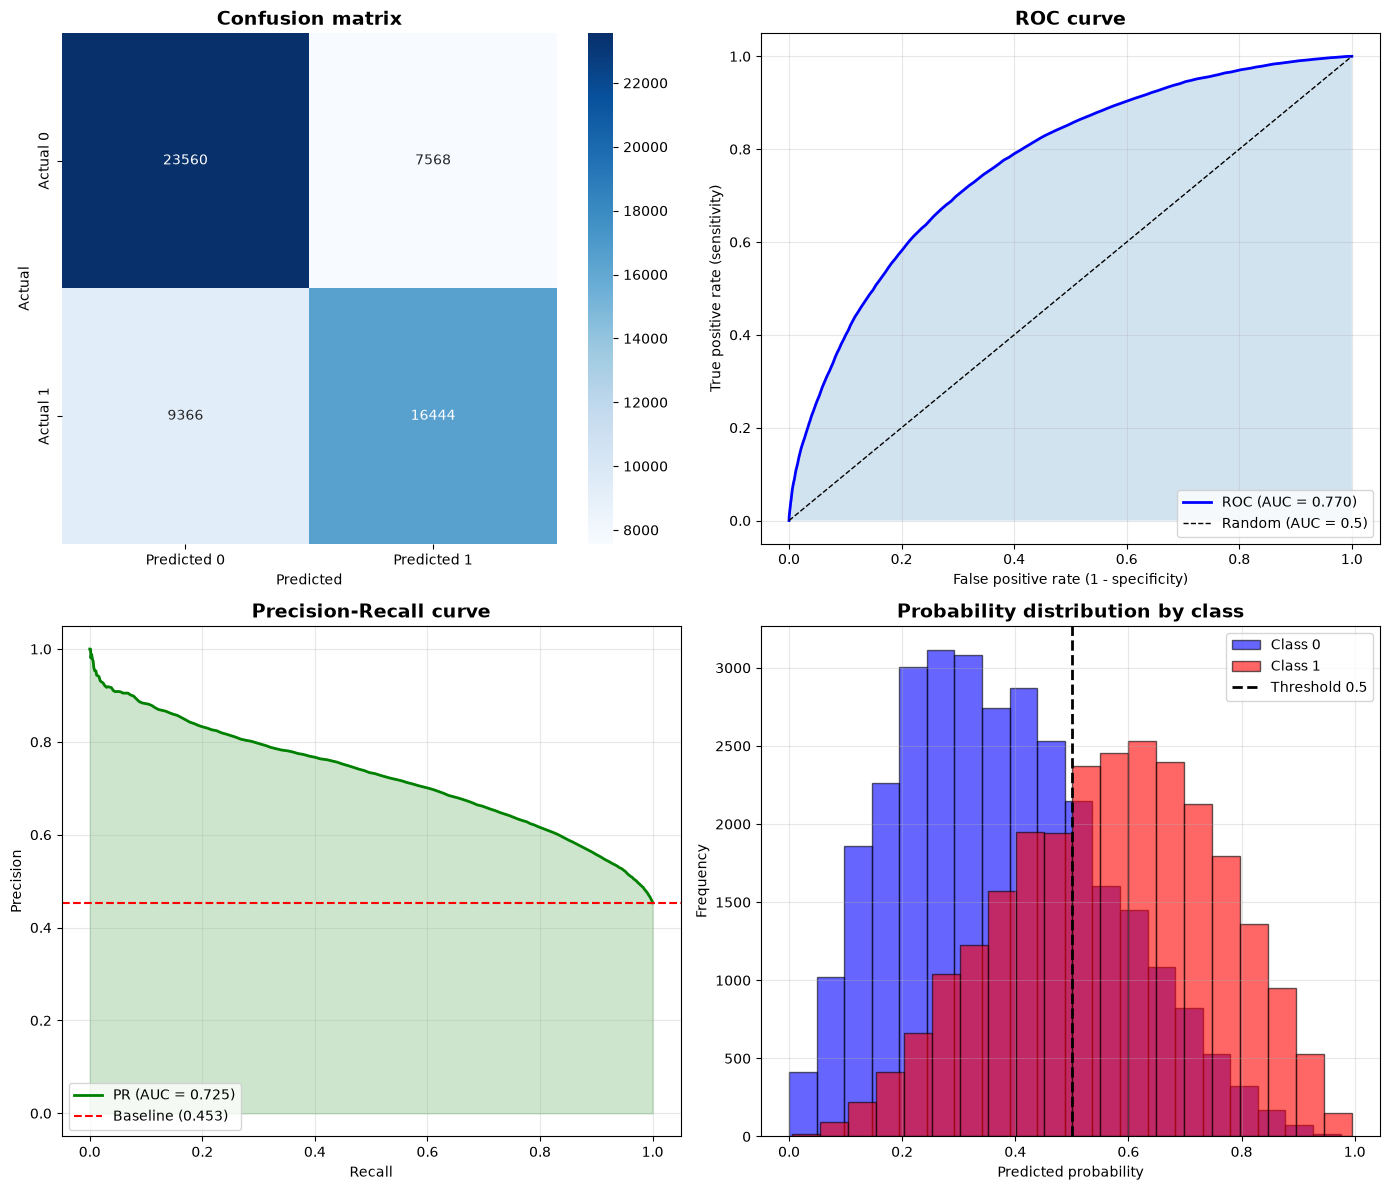

In [5]:
# =============================================================================
# CELL 3: FULL EVALUATION ON THE TEST SET
# =============================================================================

print("\n" + "="*70)
print("TEST SET EVALUATION")
print("="*70)

y_pred_test = trainer.predict(X_test)
y_proba_test = trainer.predict_proba(X_test)[:, 1]

metrics_test = full_evaluation(
    y_true=y_test,
    y_pred=y_pred_test,
    y_proba=y_proba_test,
    model_name=f"{trainer.model_name}_test",
    save_dir='results'
)

# Show the plots
plt.show()

## Random Forest Results Analysis

### Model Performance (test pairs)
- **ROC-AUC: 0.770**: second of four models, behind logistic regression (0.776)
- **Accuracy: 70.3%**: second, behind logistic regression (70.6%)
- **Brier Score: 0.195**: second, behind logistic regression (0.193)
- **Log Loss: 0.573**: second, behind logistic regression (0.568)

